# 16 — WAF-A-MoLE dataseti

**Sual:** başqa bir açıq SQLi datasetində də format artefaktı varmı və bizim modellər ona necə köçür?

- Dataset: `zangobot/wafamole_dataset` (Demetrio et al., SAC 2020), sabit commit. Repoda lisenziya faylı yoxdur — dataset paylanmır, yalnız istinad olunur.
- Birləşdirmə: README-dəki kimi `cat attacks.sql.* / sane.sql.*` (bayt-bayt, CRLF çevrilməsi olmadan).
  **Bölmə:** README `sqlparse.split()` tövsiyə edir, lakin hücum faylında generator payload-ları dırnaqları escape etmədən literal içinə qoyur
  və sqlparse sonrakı sorğuları bir-birinə yapışdırır (bölmə 1-də sübut). Ona görə fayl generatorun dörd şablonunun başlanğıcında
  (`;\n` + `SELECT`/`INSERT INTO `tab``/`UPDATE `tab``/`DELETE FROM `tab``) kəsilir, şablona uymayan hissə (yalnız `sane.sql`-in DDL başlığı)
  `sqlparse.split()` ilə bölünür (`src/wafamole.py`).
- Dublikatlar silinir; hər iki sinifdə olan sorğular çıxarılır.
- Artefakt statistikası 10-cu notebook-un cədvəli ilə eyni formatda (ikiqat boşluq, `=` ətrafında boşluq, mötərizə daxilində boşluq, böyük hərf, median uzunluq) + bizim datasetlə üst-üstə düşmə.
- 20 000 hücum + 20 000 təmiz sorğuluq təsadüfi nümunə (seed 42): seed 42 modellərinin (12/14 ilə eyni TF-IDF modelləri, 13-ün CNN-i, qara siyahı, libinjection) recall və FPR-i, normal və alternativ whitespace ilə (hər iki sinifə tətbiq olunur).
- Əks test: baza LR (eyni TF-IDF, eyni C grid) WAF-A-MoLE-də öyrədilir (nümunədən kənar 20 000 + 20 000 train, 5 000 + 5 000 val) və Kaggle, HttpParams, payload siyahılarında test olunur.

In [1]:
import re, sys, time
from pathlib import Path
from urllib.parse import unquote

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import handwritten as hw
import obfuscation as obf
import wafamole as wm
from charcnn import CONFIGS as CNN_CONFIGS, get_cnn
from detectors import BL_INPUT, BL_SEARCH, GRID_BASE, GRID_DEF, LIBINJ, fit_tuned, train_all
from experiments import group_key, leakage_free, load_clean, load_httpparams, make_split, rates
from normalize import human_format, normalize

SEED = 42
RES, FIG = ROOT / "results", ROOT / "figures" / "paper"
FIG.mkdir(parents=True, exist_ok=True)
clean, hp_all, payloads = load_clean(), load_httpparams(), hw.load()
wm.fetch()
print("commit", wm.COMMIT)

commit 3eb1cef05210be04e8c55d6b45e7e2d0933803ae


## 1. Bölmə: README üsulu (sqlparse) və şablon sərhədləri

In [2]:
# sqlparse çox yavaşdır (~3 µs/simvol), ona görə müqayisə hər faylın ilk 20 MB-ında aparılır
rep = pd.DataFrame([wm.split_report(p, n_bytes=20_000_000) for p in ("attacks", "sane")])
rep.to_csv(RES / "16_split_report.csv", index=False)
rep

,file,bytes,sqlparse_statements,sqlparse_max_len,sqlparse_over_2000_chars,sqlparse_share_of_bytes_in_over_2000,template_split_statements,identical_statements
0,attacks.sql,19999954,3262,18944655,46,0.967555,117029,2667
1,sane.sql,19999967,91586,111134,676,0.658042,264925,88138


In [3]:
wam_raw = wm.load()
n_raw = wam_raw.Label.value_counts()
wam = wam_raw.drop_duplicates()
both = set(wam.loc[wam.Label == 0, "Query"]) & set(wam.loc[wam.Label == 1, "Query"])
wam = wam[~wam.Query.isin(both)].reset_index(drop=True)
counts = pd.DataFrame({"statements": n_raw, "unique": wam_raw.drop_duplicates().Label.value_counts(),
                       "after_removing_both_classes": wam.Label.value_counts()}).rename(index={1: "attacks", 0: "sane"})
counts.loc["in_both_classes"] = [np.nan, np.nan, len(both)]
counts.to_csv(RES / "16_counts.csv")
counts

,statements,unique,after_removing_both_classes
Label,,,
sane,1000209.0,923425.0,915072
attacks,1004669.0,745593.0,737240
in_both_classes,NaN,NaN,8353


## 2. Artefakt statistikası (10-cu notebook-un cədvəli ilə eyni format)
Üst-üstə düşmə: `clean_v2` ilə boşluq-normallaşdırılmış (`group_key`) və tam normallaşdırılmış (`normalize`) formada.

In [4]:
ours_ws = set(clean.Query.map(group_key))
ours_norm = set(clean.Query.map(normalize))

def fmt_stats(name, d, overlap=True):
    rows = []
    for lab, cls in ((1, "zərərli"), (0, "təmiz")):
        q = d.loc[d.Label == lab, "Query"]
        r = {"dataset": name, "class": cls, "n": len(q),
             "double_space_pct": 100 * q.str.contains("  ", regex=False).mean(),
             "space_around_eq_pct": 100 * q.str.contains(" = ", regex=False).mean(),
             "space_inside_paren_pct": 100 * q.str.contains(r"\( | \)", regex=True).mean(),
             "has_uppercase_pct": 100 * q.str.contains(r"[A-Z]", regex=True).mean(),
             "median_len": q.str.len().median()}
        if overlap:
            r["overlap_ours_ws_pct"] = 100 * q.map(group_key).isin(ours_ws).mean()
            r["overlap_ours_norm_pct"] = 100 * q.map(normalize).isin(ours_norm).mean()
        rows.append(r)
    return rows

art = pd.DataFrame(fmt_stats("Modified_SQL_Dataset", clean, overlap=False) + fmt_stats("HttpParamsDataset", hp_all)
                   + fmt_stats("WAF-A-MoLE", wam)).round(1)
art.to_csv(RES / "16_artifact_stats.csv", index=False)
art

,dataset,class,n,double_space_pct,space_around_eq_pct,space_inside_paren_pct,has_uppercase_pct,median_len,overlap_ours_ws_pct,overlap_ours_norm_pct
0,Modified_SQL_Dataset,zərərli,11370,94.9,81.1,86.9,2.0,85.5,NaN,NaN
1,Modified_SQL_Dataset,təmiz,18885,29.8,14.8,24.4,61.3,37.0,NaN,NaN
2,HttpParamsDataset,zərərli,10852,0.0,0.0,0.0,0.0,75.0,3.6,79.1
3,HttpParamsDataset,təmiz,19304,0.0,0.0,0.0,0.0,9.0,37.3,37.3
4,WAF-A-MoLE,zərərli,737240,3.5,52.8,22.4,100.0,174.0,0.0,0.0
5,WAF-A-MoLE,təmiz,915072,0.0,47.4,22.7,100.0,70.0,0.0,0.0


In [5]:
# Hücum sorğusu = generator şablonu + payload. Siniflər arasında başqa format fərqləri:
def extra(q):
    return pd.Series({"has_newline_pct": 100 * q.str.contains("\n", regex=False).mean(),
                      "has_comment_pct": 100 * q.str.contains(r"--|#|/\*", regex=True).mean(),
                      "starts_select_pct": 100 * q.str.startswith("SELECT").mean(),
                      "starts_insert_pct": 100 * q.str.startswith("INSERT").mean(),
                      "starts_update_pct": 100 * q.str.startswith("UPDATE").mean(),
                      "starts_delete_pct": 100 * q.str.startswith("DELETE").mean()})
ex = pd.DataFrame({cls: extra(wam.loc[wam.Label == lab, "Query"]) for lab, cls in ((1, "zərərli"), (0, "təmiz"))}).round(1)
ex.to_csv(RES / "16_extra_format_stats.csv")
ex

,zərərli,təmiz
has_newline_pct,28.6,0.0
has_comment_pct,58.9,0.0
starts_select_pct,30.7,26.5
starts_insert_pct,18.6,22.7
starts_update_pct,27.3,26.0
starts_delete_pct,23.4,24.8


## 3. 20 000 + 20 000 nümunə: bizim modellər (seed 42)
Alternativ whitespace (`alt_whitespace`) hər iki sinfin sorğularına tətbiq olunur; dəyişməyən sorğular (boşluqsuz) olduğu kimi qalır.

In [6]:
rng = np.random.RandomState(SEED)
idx_mal = wam.index[wam.Label == 1].to_numpy()
idx_ben = wam.index[wam.Label == 0].to_numpy()
pick_mal = rng.permutation(idx_mal)
pick_ben = rng.permutation(idx_ben)
eval_idx = np.concatenate([pick_mal[:20000], pick_ben[:20000]])
sample = wam.loc[eval_idx].reset_index(drop=True)
# Əks test üçün nümunədən kənar train/val (bölmə 4)
wtrain = wam.loc[np.concatenate([pick_mal[20000:40000], pick_ben[20000:40000]])].reset_index(drop=True)
wval = wam.loc[np.concatenate([pick_mal[40000:45000], pick_ben[40000:45000]])].reset_index(drop=True)

def alt_ws(qs, seed=SEED):
    return [r["obfuscated"] for r in obf.apply_technique("alt_whitespace", list(qs), seed=seed)]

sample_aw = sample.assign(Query=alt_ws(sample.Query))
print(sample.Label.value_counts().to_dict(), "alt_ws dəyişən:", (sample_aw.Query != sample.Query).mean())

train42, val42, test42 = make_split(clean, SEED)
dets = {k: m.predict for k, m in train_all(SEED, train42, val42).items()}
for cfg in CNN_CONFIGS:
    dets[cfg] = get_cnn(cfg, SEED, train42, val42).predict
dets.update({"Qara siyahı (sanitizeInput)": BL_INPUT, "Qara siyahı (sanitizeSearch)": BL_SEARCH,
             "libinjection 4.0.1": LIBINJ})

rows = []
for name, det in dets.items():
    t0 = time.perf_counter()
    for variant, d in (("normal", sample), ("alt_whitespace", sample_aw)):
        r = rates(d.Label, det(d.Query))
        rows.append({"detector": name, "input": variant, "recall": r["recall"], "fpr": r["fpr"], "f1": r["f1"]})
    print(f"{name:30s} {time.perf_counter() - t0:.0f} s")
ours_on_wam = pd.DataFrame(rows)
ours_on_wam.to_csv(RES / "16_our_models_on_wafamole.csv", index=False)
tbl = ours_on_wam.pivot(index="detector", columns="input", values=["recall", "fpr"]).mul(100).round(2)
tbl = tbl.loc[list(dets)]
tbl

{1: 20000, 0: 20000} alt_ws dəyişən: 1.0


LR baza                        53 s


SVM baza                       53 s


RF baza                        59 s


NB baza                        1393 s


LR + normallaşdırma            46 s


... (3 outputs left out)

Qara siyahı (sanitizeInput)    3 s


Qara siyahı (sanitizeSearch)   2 s


libinjection 4.0.1             1 s


recall                    fpr        
input                        alt_whitespace  normal alt_whitespace  normal
detector                                                                  
LR baza                               86.56   90.82          10.03   21.31
SVM baza                              79.09   88.80           1.97   11.88
RF baza                               19.50   70.12           0.00   18.84
NB baza                               77.58   80.54          35.62   21.62
LR + normallaşdırma                   95.94   95.94          26.54   26.54
LR + norm. + augmentation             95.24   95.24          21.72   21.72
CNN baza                               2.34   46.50           0.00    3.73
CNN + normallaşdırma                  95.50   95.50          39.95   39.95
Qara siyahı (sanitizeInput)          100.00  100.00         100.00  100.00
Qara siyahı (sanitizeSearch)         100.00  100.00         100.00  100.00
libinjection 4.0.1                    77.90   78.11          45.06   45.06

## 4. Əks test: baza LR WAF-A-MoLE-də öyrədilir
TF-IDF (char 1–5) + LR, C ∈ {0.1, 1, 10, 100} WAF-A-MoLE val F1-ə görə; müqayisə üçün eyni prosedurla LR + normallaşdırma (C ∈ {1, 10, 100}).
Test: WAF-A-MoLE nümunəsi (bölmə 3), Kaggle test (seed 42) və onun "insan formatı", HttpParams (təmiz + zərərli), əl ilə yazılmış payload-lar
(recall; train-də olmadığı üçün sızma çıxarılmır). Hər zərərli dəst üçün alternativ whitespace (ssenari A) recall-u da verilir.

In [7]:
y_w = wtrain.Label.to_numpy()
w_models = {}
w_models["LR baza (WAF-A-MoLE)"], c_base, _ = fit_tuned("LR", GRID_BASE["LR"], SEED, wtrain.Query, y_w, wval)
w_models["LR + norm. (WAF-A-MoLE)"], c_norm, _ = fit_tuned("LR", GRID_DEF["LR"], SEED, wtrain.Query, y_w, wval, prep=normalize)
print("C:", c_base, c_norm)

test_h = test42.assign(Query=test42.Query.map(human_format))
k_mal = test42.loc[test42.Label == 1, "Query"]
hp_mal = hp_all.loc[hp_all.Label == 1, "Query"]
sets = {"WAF-A-MoLE nümunə": sample, "Kaggle test": test42, "Kaggle test, insan formatı": test_h, "HttpParams": hp_all}
mal_sets = {"WAF-A-MoLE nümunə": sample.loc[sample.Label == 1, "Query"], "Kaggle test": k_mal.map(unquote),
            "HttpParams": hp_mal, "Əl ilə yazılmış payload-lar": payloads.Query}
rows = []
for mname, m in w_models.items():
    for sname, d in sets.items():
        r = rates(d.Label, m.predict(d.Query))
        rows.append({"model": mname, "test": sname, "metric": "recall", "value": r["recall"]})
        rows.append({"model": mname, "test": sname, "metric": "fpr", "value": r["fpr"]})
        rows.append({"model": mname, "test": sname, "metric": "f1", "value": r["f1"]})
    rows.append({"model": mname, "test": "Əl ilə yazılmış payload-lar", "metric": "recall", "value": m.predict(payloads.Query).mean()})
    for sname, q in mal_sets.items():
        aw = [x for x, o in zip(alt_ws(q), q) if x != o]
        rows.append({"model": mname, "test": sname, "metric": "recall_alt_whitespace", "value": m.predict(aw).mean()})
rev = pd.DataFrame(rows)
rev.to_csv(RES / "16_reverse_lr_trained_on_wafamole.csv", index=False)
rev_tbl = rev.pivot_table(index=["test"], columns=["model", "metric"], values="value").mul(100).round(2)
rev_tbl = rev_tbl.loc[["WAF-A-MoLE nümunə", "Kaggle test", "Kaggle test, insan formatı", "HttpParams", "Əl ilə yazılmış payload-lar"]]
rev_tbl

C: 10 100


model                       LR + norm. (WAF-A-MoLE)                \
metric                                           f1    fpr recall   
test                                                                
WAF-A-MoLE nümunə                             99.64   0.39  99.67   
Kaggle test                                   64.04  58.05  90.89   
Kaggle test, insan formatı                    64.04  58.05  90.89   
HttpParams                                    93.78   3.40  93.63   
Əl ilə yazılmış payload-lar                     NaN    NaN  96.92   

model                                             LR baza (WAF-A-MoLE)         \
metric                      recall_alt_whitespace                   f1    fpr   
test                                                                            
WAF-A-MoLE nümunə                           99.67                99.79   0.30   
Kaggle test                                 91.45                68.58  36.65   
Kaggle test, insan formatı                    NaN                71.18  31.53   
HttpParams                                  94.13                97.47   0.02   
Əl ilə yazılmış payload-lar                 97.65                  NaN    NaN   

model                                                     
metric                      recall recall_alt_whitespace  
test                                                      
WAF-A-MoLE nümunə            99.87                 97.18  
Kaggle test                  82.81                 56.81  
Kaggle test, insan formatı   83.15                   NaN  
HttpParams                   95.10                 76.85  
Əl ilə yazılmış payload-lar  92.15                 79.77

In [8]:
# LR-in ən güclü n-gram-ları (WAF-A-MoLE-də öyrədilmiş baza LR): şablon/format siqnalı varmı?
m = w_models["LR baza (WAF-A-MoLE)"]
vocab = np.array(m.vec.get_feature_names_out())
coef = m.clf.coef_[0]
top = pd.DataFrame({"zərərli_ngram": [repr(x) for x in vocab[np.argsort(-coef)[:25]]], "zərərli_coef": np.sort(coef)[::-1][:25].round(2),
                    "təmiz_ngram": [repr(x) for x in vocab[np.argsort(coef)[:25]]], "təmiz_coef": np.sort(coef)[:25].round(2)})
top.to_csv(RES / "16_wafamole_lr_top_ngrams.csv", index=False)
top

,zərərli_ngram,zərərli_coef,təmiz_ngram,təmiz_coef
0,"'""'",13.14,'j',-6.55
1,')',11.12,'z',-5.84
2,'=',7.99,' -',-5.77
3,"' ""'",7.96,'q',-5.76
4,' a',7.76,'y',-4.36
5,'--',7.40,'-1',-4.28
6,') ',7.39,' -1',-4.12
7,""" '""",6.88,'k',-3.89
8,"""'""",6.80,'t -',-3.75
9,"','",6.57,'mit -',-3.75


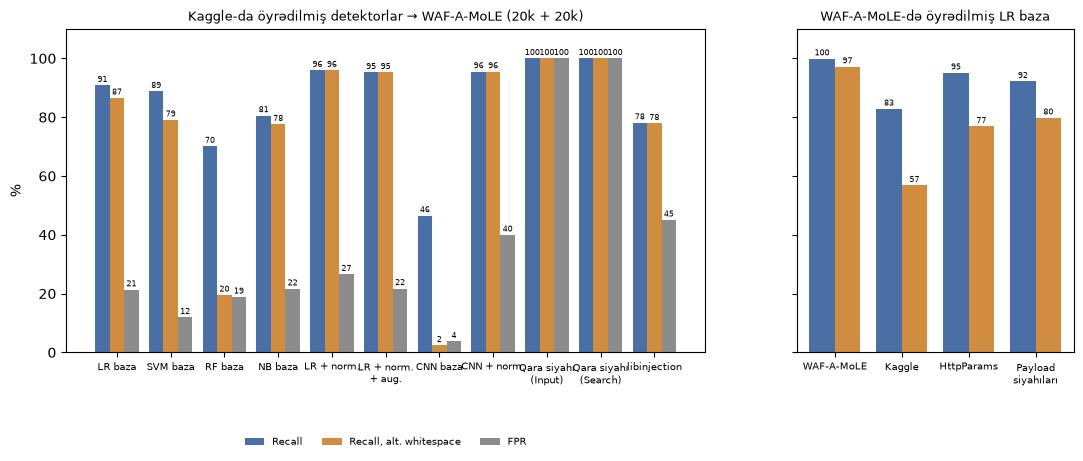

In [9]:
order = list(dets)
labels = [n.replace(" (sanitizeInput)", "\n(Input)").replace(" (sanitizeSearch)", "\n(Search)").replace("normallaşdırma", "norm.")
          .replace(" + augmentation", "\n+ aug.").replace("libinjection 4.0.1", "libinjection") for n in order]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True, gridspec_kw={"width_ratios": [3, 1.3]})
ax = axes[0]
x, w = np.arange(len(order)), 0.27
for i, (col, metric, variant, lab) in enumerate([("#4a6fa5", "recall", "normal", "Recall"),
                                                  ("#d08c3f", "recall", "alt_whitespace", "Recall, alt. whitespace"),
                                                  ("#8c8c8c", "fpr", "normal", "FPR")]):
    v = tbl[(metric, variant)].loc[order]
    b = ax.bar(x + (i - 1) * w, v, w, color=col, label=lab)
    ax.bar_label(b, fmt="%.0f", fontsize=6, padding=1)
ax.set_xticks(x, labels, fontsize=7)
ax.set_ylabel("%")
ax.set_ylim(0, 110)
ax.set_title("Kaggle-da öyrədilmiş detektorlar → WAF-A-MoLE (20k + 20k)", fontsize=9)
ax.legend(fontsize=7, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.32), frameon=False)
ax = axes[1]
tests = ["WAF-A-MoLE nümunə", "Kaggle test", "HttpParams", "Əl ilə yazılmış payload-lar"]
x2 = np.arange(len(tests))
for i, (metric, col, lab) in enumerate([("recall", "#4a6fa5", "Recall"), ("recall_alt_whitespace", "#d08c3f", "Recall, alt. ws")]):
    sel = rev[(rev.model == "LR baza (WAF-A-MoLE)") & (rev.metric == metric)].set_index("test").value
    v = [sel[t] * 100 for t in tests]
    b = ax.bar(x2 + (i - 0.5) * 0.38, v, 0.38, color=col, label=lab)
    ax.bar_label(b, fmt="%.0f", fontsize=6, padding=1)
ax.set_xticks(x2, ["WAF-A-MoLE", "Kaggle", "HttpParams", "Payload\nsiyahıları"], fontsize=7)
ax.set_title("WAF-A-MoLE-də öyrədilmiş LR baza", fontsize=9)
fig.savefig(FIG / "16_wafamole.png", dpi=300, bbox_inches="tight")
plt.show()